# LAB 06 — Attention Mechanism

Notebook chạy được từ thư mục gốc hoặc `lab6`. Các heatmap minh họa dùng đặc trưng tự thiết kế và được khai báo rõ. Classifier sentiment được huấn luyện theo cách chia tập IMDb của Lab 05. Xem `calculations.md` để theo dõi bài tính tay và `prediction.md` để xem các dự đoán cho thí nghiệm.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
LAB = ROOT / 'lab6' if (ROOT / 'lab6').exists() else ROOT
sys.path.insert(0, str(LAB))
from attention_numpy import stable_softmax, scaled_dot_product_attention, self_attention, verify_examples
from run_lab6 import Config, run_numpy_experiments, main
import numpy as np
import pandas as pd
from IPython.display import display, Image
assert verify_examples()

## Q, K, V và stable softmax

Query biểu diễn thông tin cần tìm, key quyết định mức khớp, còn value cung cấp nội dung để tổng hợp. Mỗi hàng của ma trận score được chuẩn hóa theo các key. Trừ giá trị lớn nhất của hàng giúp tránh tràn số.

In [2]:
Q = np.array([[1., 0.]])
K = np.array([[1., 0.], [0., 1.], [1., 1.]])
V = np.array([[1., 0.], [0., 2.], [2., 1.]])
scores, weights, context = scaled_dot_product_attention(Q, K, V)
print('Score sau scaling:', scores)
print('Weights:', weights, 'tổng theo hàng:', weights.sum(axis=1))
print('Context:', context)
print('Score rất lớn:', stable_softmax(np.array([1000., 1001., 1002.])))

Score sau scaling: [[0.70710678 0.         0.70710678]]
Weights: [[0.40111209 0.19777581 0.40111209]] tổng theo hàng: [1.]
Context: [[1.20333628 0.79666372]]
Score rất lớn: [0.09003057 0.24472847 0.66524096]


## Scaling và temperature

Ví dụ dùng score gốc `[4, 2, 0]` và `d_k=4`. Temperature thấp làm softmax tập trung hơn; temperature cao làm entropy tăng.

In [3]:
demo = run_numpy_experiments(Config())
print('Chưa scaling:', demo['scaling']['unscaled'])
print('Đã scaling:', demo['scaling']['scaled'])
temperature_table = pd.DataFrame(demo['temperature']).T[['max_weight', 'entropy_nats']]
display(temperature_table.rename(columns={'max_weight': 'Weight lớn nhất', 'entropy_nats': 'Entropy (nat)'}))

Chưa scaling: [0.8668133321973347, 0.11731042782619835, 0.015876239976466762]
Đã scaling: [0.6652409557748218, 0.24472847105479764, 0.09003057317038046]


,Weight lớn nhất,Entropy (nat)
0.5,0.98169,0.093035
1.0,0.866813,0.441057
2.0,0.665241,0.832396


## Phân phối thay đổi theo query

Câu ví dụ dùng đặc trưng được gán rõ, không phải word embedding đã học. Query sentiment dự kiến nhấn mạnh `good`; query topic dự kiến nhấn mạnh `movie` và `beginning`. Thí nghiệm cho thấy sự phụ thuộc vào query nhưng không chứng minh mô hình hiểu ngôn ngữ.

,token,sentiment_score,topic_score,sentiment_attention,topic_attention
0,The,0.00,0.0,0.056907,0.051429
1,movie,0.00,2.0,0.056907,0.380012
2,was,0.00,0.0,0.056907,0.051429
3,surprisingly,0.40,0.0,0.084895,0.051429
4,good,2.00,0.0,0.420487,0.051429
5,despite,0.20,0.0,0.069506,0.051429
6,a,0.00,0.0,0.056907,0.051429
7,very,0.00,0.0,0.056907,0.051429
8,slow,0.35,0.0,0.080754,0.051429
9,beginning,0.05,1.4,0.059824,0.208555


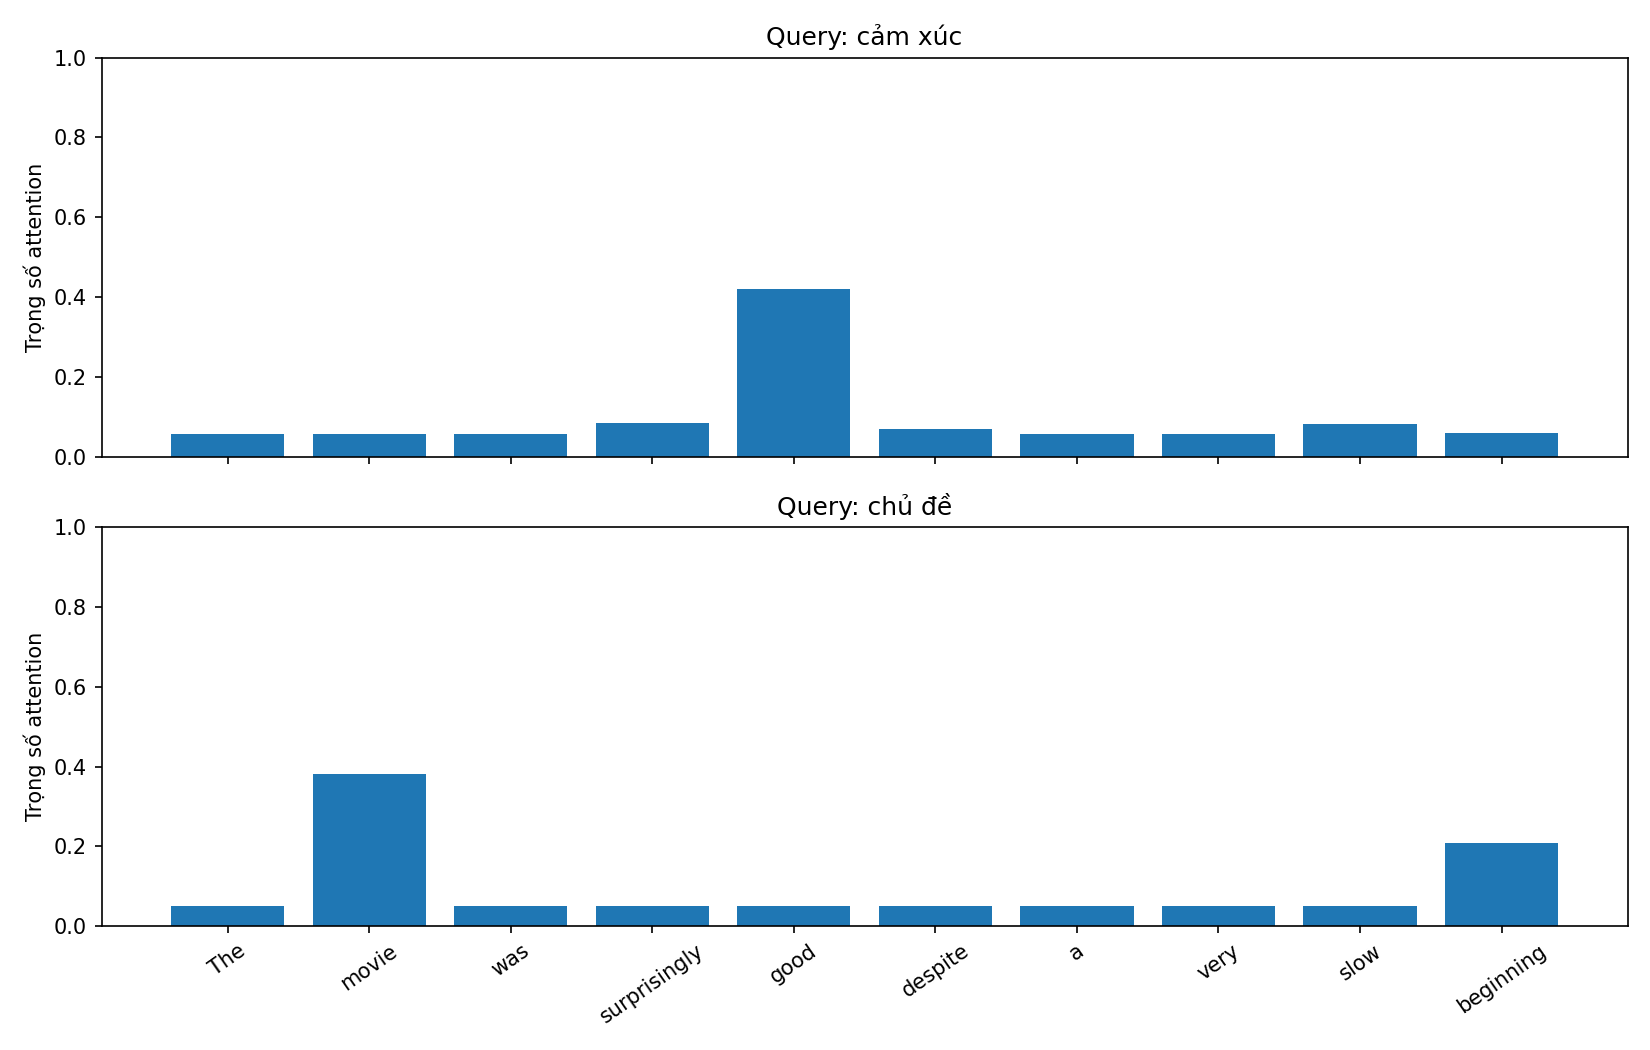

In [4]:
tokens = list(Config().demo_tokens)
display(pd.DataFrame({'token': tokens, **{f'{name}_score': result['scores'] for name, result in demo['query_experiment'].items()}, **{f'{name}_attention': result['weights'] for name, result in demo['query_experiment'].items()}}))
display(Image(filename=str(LAB / 'query_attention.png')))

## Self-attention và heatmap

Với `I like cats`, các ma trận chiếu đơn vị và embedding 3×2 đã nêu cho phép kiểm tra từng phép tính. Hai heatmap còn lại dùng đặc trưng 3 chiều tự thiết kế. Hàng là query, cột là key. Hãy xem các hàng `cat`, `adopted`, `sleeping` mà không coi phân phối weight là bằng chứng hiểu ngữ pháp.

Q=K=V:
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
QK^T:
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]
Weights:
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]
Context:
 [[0.8022 0.5989]
 [0.5989 0.8022]
 [0.7517 0.7517]]


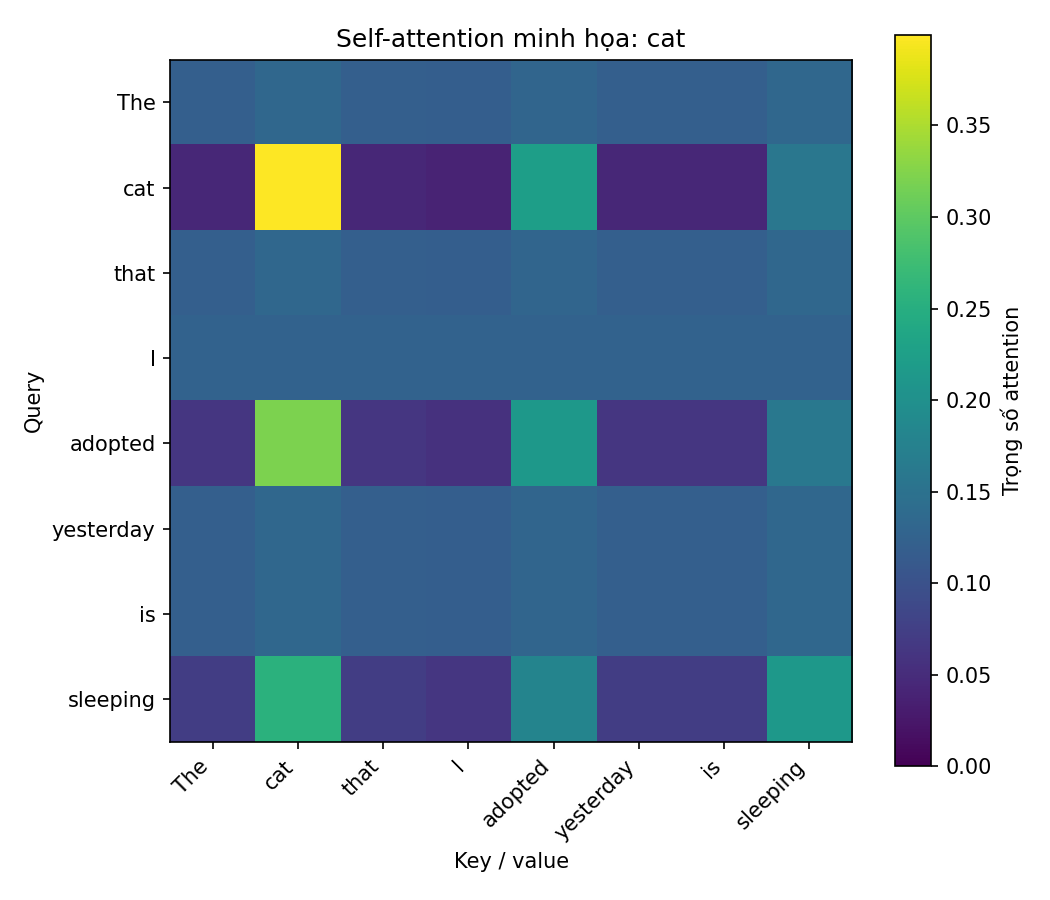

cat [('cat', 0.39941867891922384), ('adopted', 0.22422722121607128), ('sleeping', 0.15857850281994312)]
adopted [('cat', 0.3203633548542269), ('adopted', 0.2126265083029491), ('sleeping', 0.16023404257243692)]
sleeping [('cat', 0.2556347615664775), ('sleeping', 0.21251182353565515), ('adopted', 0.18079061738396823)]


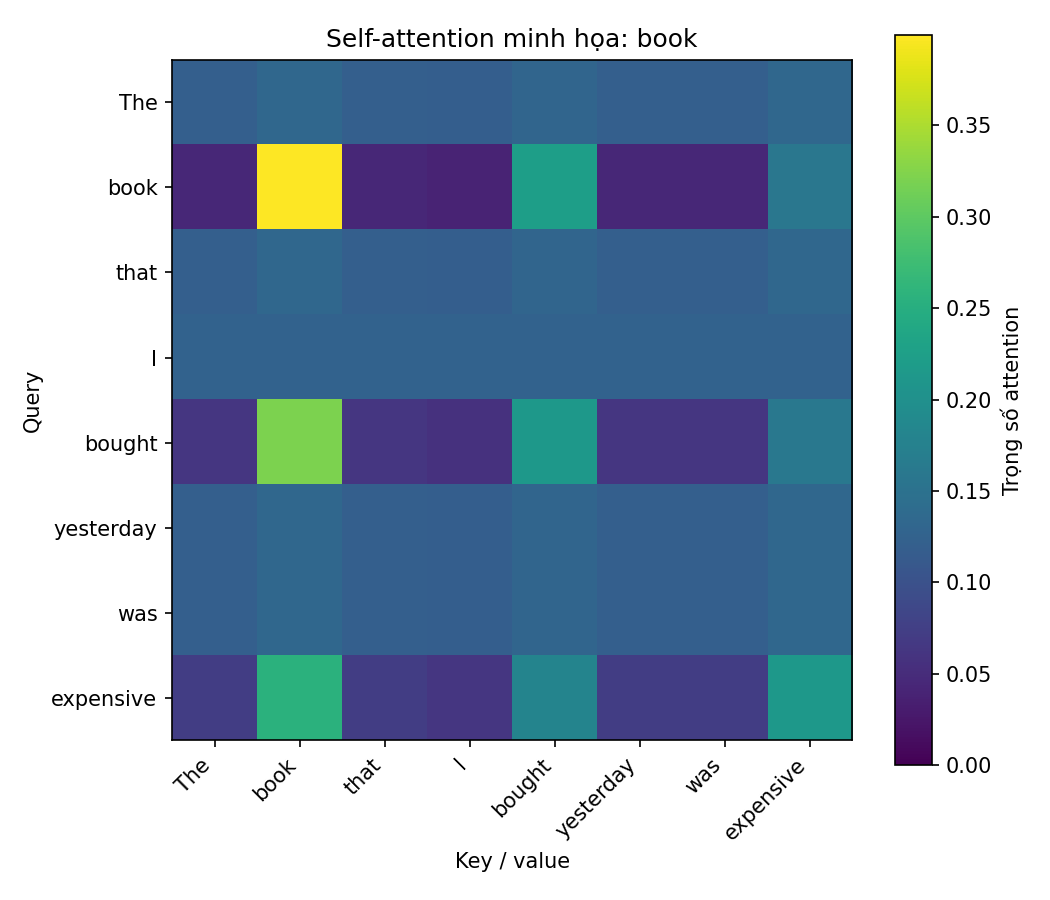

In [5]:
X = np.array([[1., 0.], [0., 1.], [1., 1.]])
Q, K, V, scores, weights, context = self_attention(X, np.eye(2), np.eye(2), np.eye(2))
print('Q=K=V:\n', Q)
print('QK^T:\n', Q @ K.T)
print('Weights:\n', np.round(weights, 4))
print('Context:\n', np.round(context, 4))
display(Image(filename=str(LAB / 'attention_heatmap.png')))
cat_demo = demo['semantic'][Config().semantic_sentences[0]]
for token in ('cat', 'adopted', 'sleeping'):
    position = cat_demo['tokens'].index(token)
    print(token, sorted(zip(cat_demo['tokens'], cat_demo['weights'][position]), key=lambda item: item[1], reverse=True)[:3])
display(Image(filename=str(LAB / 'attention_heatmap_book.png')))

## Chi phí theo độ dài chuỗi

Ma trận full self-attention `T×T` có `T²` phần tử. Bảng chưa tính batch, tensor Q/K/V, gradient và trạng thái optimizer.

In [6]:
display(pd.DataFrame([{'Độ dài': int(length), 'Số phần tử ma trận': count, 'Bộ nhớ float32 (byte)': 4 * count} for length, count in demo['sequence_cost'].items()]))

,Độ dài,Số phần tử ma trận,Bộ nhớ float32 (byte)
0,10,100,400
1,100,10000,40000
2,500,250000,1000000
3,1000,1000000,4000000
4,10000,100000000,400000000


## Phân loại sentiment trên IMDb

Chạy ô dưới để huấn luyện lại mô hình embedding → self-attention → masked mean context → classifier. Ô tạo lại `results.csv`, confusion matrix và ba biểu đồ attention của phần ứng dụng. Mô hình chưa có positional encoding; xem giới hạn trong `reflection.md`.

{
  "accuracy": 0.707,
  "f1": 0.7185398655139289,
  "confusion_matrix": [
    [
      333,
      167
    ],
    [
      126,
      374
    ]
  ],
  "model": "Self-Attention",
  "max_length": 100,
  "parameters": 780545,
  "training_time_seconds": 5.497635399999581,
  "epochs": 2
}


,model,accuracy,f1,training_time_seconds,parameters,max_length,epochs
0,LSTM,0.553,0.540596,31.901342,801345,100,2
1,Self-Attention,0.707,0.718540,5.497635,780545,100,2


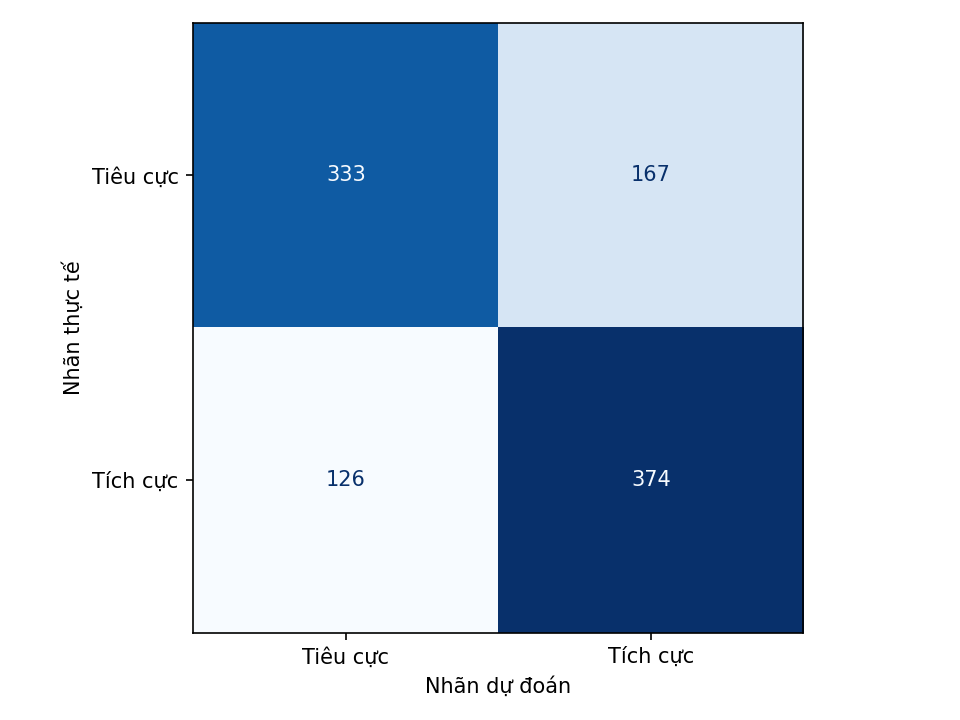

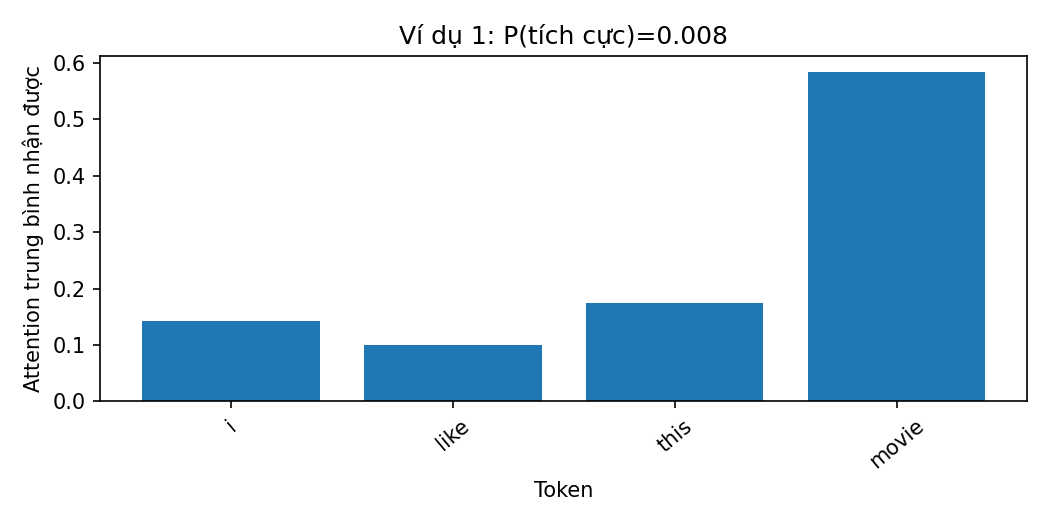

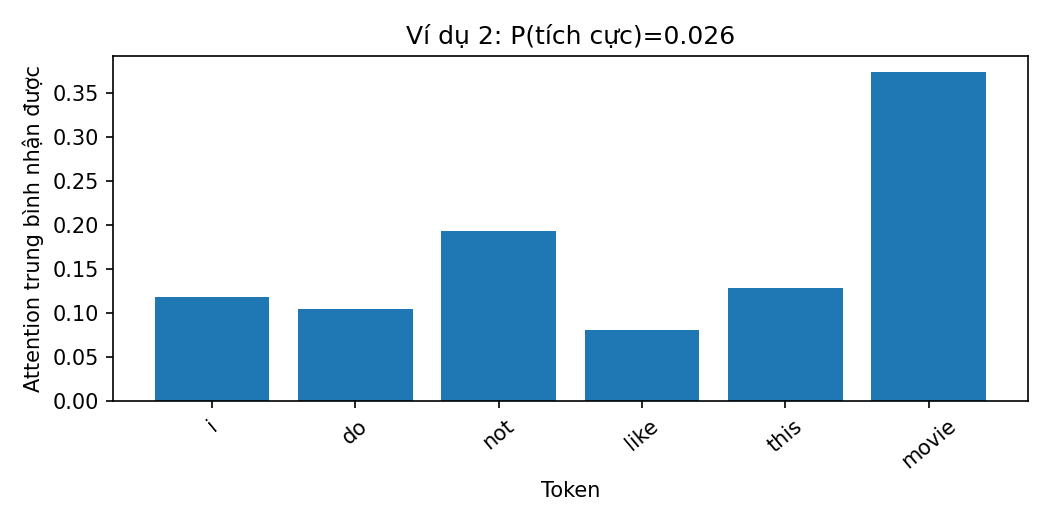

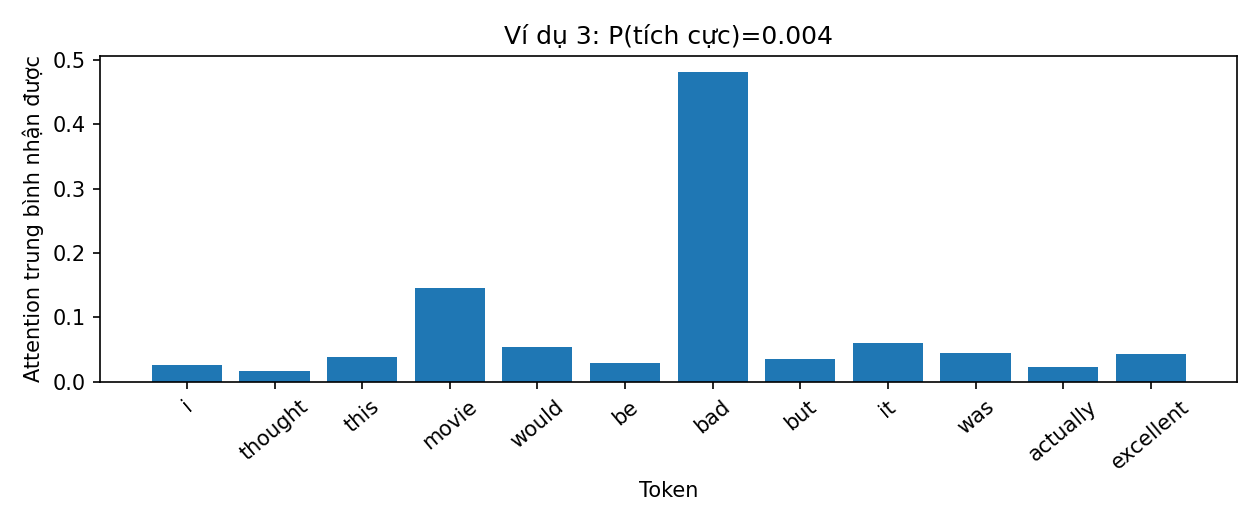

In [7]:
main()
display(pd.read_csv(LAB / 'results.csv'))
display(Image(filename=str(LAB / 'confusion_matrix.png')))
for index in range(1, 4):
    display(Image(filename=str(LAB / f'application_attention_{index}.png')))

## Diễn giải kết quả

Đối chiếu phân phối attention với nhãn thật và dự đoán. Một token nhận attention không chứng minh nó gây ra dự đoán. `error_analysis.md` ghi ba trường hợp đúng, ba trường hợp sai trên tập test và trình bày nguyên nhân có thể xảy ra dưới dạng giả thuyết. Hàng LSTM lấy từ Lab 05, dùng cùng các tập train/validation/test, độ dài chuỗi, kích thước embedding và số epoch; classifier dựa trên hidden state hồi quy có kiến trúc và chi phí tính toán khác.